# Tokenización y Representaciones Vectoriales en LLMs

## ¿Qué es la tokenización?

Antes de que un modelo de lenguaje como GPT o BERT pueda procesar texto, necesita convertir las palabras (o partes de palabras) en números. Este proceso se llama **tokenización**.

Un **token** es la unidad básica de texto que el modelo "ve". Puede ser:
- Una palabra completa: `"perro"` → token
- Un subpalabra: `"tokenización"` → `["token", "ización"]`
- Un carácter individual

## ¿Qué es un embedding (representación vectorial)?

Una vez tokenizado el texto, cada token se mapea a un **vector de números reales** en un espacio de alta dimensión. Este vector es el *embedding* del token.

**¿Por qué vectores?** Porque nos permiten representar el *significado semántico* de las palabras de forma matemática. Palabras con significados similares quedan **cerca** en este espacio vectorial.

```
"rey"   → [0.23, -0.81, 0.45, ..., 0.12]  (300 números)
"reina" → [0.21, -0.79, 0.48, ..., 0.15]  (300 números, ¡muy similar!)
"mesa"  → [-0.54, 0.33, -0.12, ..., 0.87] (300 números, muy diferente)
```

En este notebook usaremos **Word2Vec** (Google News), un modelo clásico entrenado sobre millones de artículos de noticias, para explorar estas representaciones.

## Paso 1 — Instalar dependencias

`gensim` es una librería de Python especializada en modelos de lenguaje y representaciones vectoriales. La usaremos para cargar modelos Word2Vec pre-entrenados sin necesidad de entrenar desde cero.

In [1]:
%matplotlib inline
# Dependencias instaladas desde requirements.txt
import gensim

## Paso 2 — Cargar el modelo Word2Vec

Cargamos el modelo `word2vec-google-news-300`, entrenado por Google sobre ~100 mil millones de palabras de artículos de noticias.

- Contiene ~3 millones de palabras/frases en su vocabulario
- Cada token está representado por un vector de **300 dimensiones**

> **Nota:** La primera vez esto descarga ~1.6 GB. Después queda en caché local.

In [2]:
import gensim.downloader as api

# Load pre-trained Word2Vec model
model = api.load("word2vec-google-news-300")

## Paso 3 — ¿Cuántas dimensiones tiene un embedding?

Verifiquemos la dimensión del vector de la palabra `"apple"`. Cada token en este modelo está representado como un punto en un espacio de **300 dimensiones**.

Aunque 300 dimensiones es imposible de visualizar directamente, podemos usar técnicas de reducción dimensional como **PCA** (Análisis de Componentes Principales) o **t-SNE** para proyectarlos en 2D o 3D y así visualizar las relaciones semánticas entre palabras.

In [3]:
len(model['apple'])

300

## Paso 4 — Aritmética vectorial: la magia de los embeddings

Una de las propiedades más fascinantes de los embeddings es que **las relaciones semánticas se preservan como operaciones vectoriales**.

El experimento clásico es:

$$\vec{king} - \vec{man} + \vec{woman} \approx \vec{queen}$$

¿Qué significa esto? El vector que va de `"man"` a `"king"` (la *dirección de realeza*) es aproximadamente el mismo que el que va de `"woman"` a `"queen"`. El modelo aprendió este concepto implícitamente al leer millones de textos — **nadie le enseñó explícitamente qué es un rey o una reina**.

### Visualización con PCA 3D

Como no podemos graficar 300 dimensiones, usamos **PCA** para reducir a 3D, buscando las tres direcciones que capturan la mayor varianza. Las líneas rojas y azules muestran la similitud coseno entre el vector resultado y `king`/`queen`.

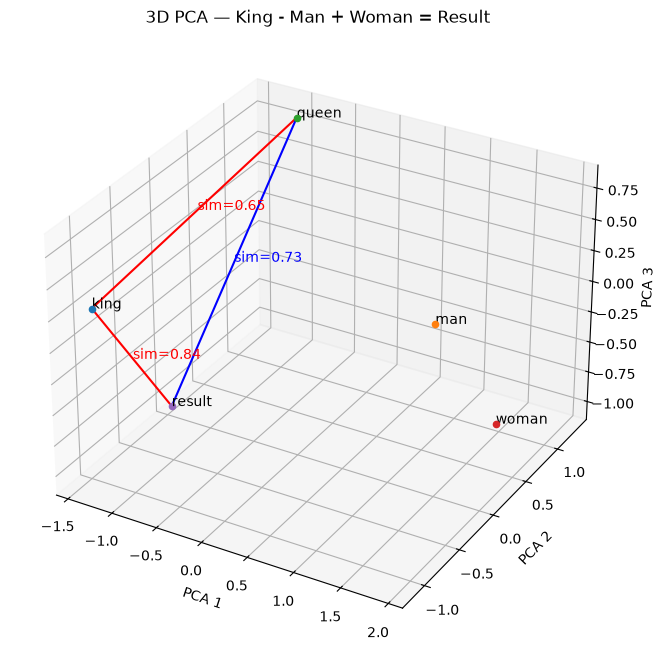

In [4]:
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np


v_king = model['king']
v_man = model['man']
v_woman = model['woman']
v_queen = model['queen']
v_result = v_king - v_man + v_woman


words_to_plot = ['king', 'man', 'queen', 'woman', 'result']
vectors_to_plot = [v_king, v_man, v_queen, v_woman, v_result]

pca = PCA(n_components=3)
reduced = pca.fit_transform(vectors_to_plot)
coords = {word: reduced[i] for i, word in enumerate(words_to_plot)}

def cos(a, b):
    return cosine_similarity([a], [b])[0, 0]

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

for word, vec in coords.items():
    ax.scatter(vec[0], vec[1], vec[2])
    ax.text(vec[0], vec[1], vec[2], word)

result = coords['result']
king = coords['king']
queen = coords['queen']

# Result ↔ King
ax.plot([result[0], king[0]], [result[1], king[1]], [result[2], king[2]], color='red')
mid_rk = (result + king) / 2.0
ax.text(mid_rk[0], mid_rk[1], mid_rk[2],
        f"sim={cos(v_result, v_king):.2f}", color='red')

# King ↔ Queen
ax.plot([king[0], queen[0]], [king[1], queen[1]], [king[2], queen[2]], color='red')
mid_kq = (king + queen) / 2.0
ax.text(mid_kq[0], mid_kq[1], mid_kq[2],
        f"sim={cos(v_king, v_queen):.2f}", color='red')

# Result ↔ Queen
ax.plot([result[0], queen[0]], [result[1], queen[1]], [result[2], queen[2]], color='blue')
mid_rq = (result + queen) / 2.0
ax.text(mid_rq[0], mid_rq[1], mid_rq[2],
        f"sim={cos(v_result, v_queen):.2f}", color='blue')

ax.set_title("3D PCA — King - Man + Woman = Result")
ax.set_xlabel("PCA 1"); ax.set_ylabel("PCA 2"); ax.set_zlabel("PCA 3")
plt.show()

## Paso 5 — ¿A qué palabras se parece el resultado?

Ahora buscamos los 10 tokens más similares al vector resultado de `king - man + woman` usando **similitud coseno**.

La similitud coseno mide el ángulo entre dos vectores en el espacio de embeddings:
- `sim = 1.0` → misma dirección (palabras idénticas o sinónimos perfectos)
- `sim ≈ 0.7` → fuertemente relacionadas
- `sim ≈ 0.0` → sin relación semántica

Si los embeddings capturaron bien la semántica, deberíamos ver `"queen"` entre los primeros resultados — y de hecho aparece en el segundo lugar.

In [5]:
similar_words = model.most_similar(positive=[v_result], topn=10)

print("Top 10 palabras mas similares a la operación 'king - man + woman':")
for word, similarity in similar_words:
    print(f"{word}: {similarity:.4f}")

Top 10 palabras mas similares a la operación 'king - man + woman':
king: 0.8449
queen: 0.7301
monarch: 0.6455
princess: 0.6156
crown_prince: 0.5819
prince: 0.5777
kings: 0.5614
sultan: 0.5377
Queen_Consort: 0.5344
queens: 0.5290


### Vecinos más cercanos de `"queen"`

Para comparar, veamos directamente los 10 tokens más similares a `"queen"`. Esto nos dice qué conceptos el modelo asocia con ser reina. Observa que `king` aparece como vecino de `queen` y viceversa — los embeddings capturaron la relación bidireccional entre estos conceptos.

In [6]:
similar_words = model.most_similar(positive=[v_queen], topn=10)

print("Top 10 palabras mas similares a la operación 'queen':")
for word, similarity in similar_words:
    print(f"{word}: {similarity:.4f}")

Top 10 palabras mas similares a la operación 'queen':
queen: 1.0000
queens: 0.7399
princess: 0.7071
king: 0.6511
monarch: 0.6384
very_pampered_McElhatton: 0.6357
Queen: 0.6163
NYC_anglophiles_aflutter: 0.6061
Queen_Consort: 0.5924
princesses: 0.5908


### Vecinos más cercanos de `"king"`

Finalmente, los 10 tokens más similares a `"king"`. Compara los vecinos de `king` vs. los de `queen`: ¿son simétricos? ¿Hay sesgos del corpus de entrenamiento que puedas identificar?

**Respuesta:** la similitud coseno entre king y queen es simétrica (0,6511 en esta ejecución), pero sus listas de diez vecinos no tienen por qué coincidir. King se relaciona con kings, monarch, prince y sultan; queen con queens, princess y referencias periodísticas como very_pampered_McElhatton. Hay asociaciones con títulos de género y nombres propios del corpus. Estas listas sugieren sesgos culturales del texto de entrenamiento, pero no bastan para medirlos rigurosamente.

In [7]:
similar_words = model.most_similar(positive=[v_king], topn=10)

print("Top 10 palabras mas similares a la operación 'king':")
for word, similarity in similar_words:
    print(f"{word}: {similarity:.4f}")

Top 10 palabras mas similares a la operación 'king':
king: 1.0000
kings: 0.7138
queen: 0.6511
monarch: 0.6413
crown_prince: 0.6204
prince: 0.6160
sultan: 0.5865
ruler: 0.5798
princes: 0.5647
Prince_Paras: 0.5433


---
## Reto: Explora tu propio espacio semántico

Ahora es tu turno. Usando el modelo Word2Vec que ya cargamos, realiza las siguientes exploraciones:

### Parte 1 — Tu animal favorito
1. Elige tu animal favorito en inglés (e.g., `"dolphin"`, `"tiger"`, `"eagle"`)
2. Obtén su vector: `v_animal = model["nombre_del_animal"]`
3. Busca los 10 tokens más similares
4. ¿Los resultados tienen sentido semántico? ¿Encuentras tokens sorprendentes?

### Parte 2 — Operaciones vectoriales
Diseña operaciones análogas a `king - man + woman` con tu animal:
- `"dog" - "domestic" + "wild"` → ¿a qué llega?
- `"eagle" - "fly" + "swim"` → ¿qué predice el modelo?
- Inventa tu propia operación semántica y explica qué esperabas y qué obtuviste

### Parte 3 — Visualización
Toma tu animal, sus vecinos más cercanos y alguna operación vectorial, y grafícalos en 3D con PCA igual que hicimos arriba. ¿Forman clusters semánticos con sentido?

> **Tip:** Si una palabra no está en el vocabulario, el modelo lanzará un `KeyError`. Verifica con `"palabra" in model.key_to_index` antes de usarla.

Dimensión: (300,)
Vecinos: [('dolphins', 0.8324888348579407), ('whale', 0.771171510219574), ('whale_shark', 0.6935760974884033), ('whales', 0.6891486048698425), ('bottlenose_dolphin', 0.6850119233131409), ('shark', 0.6842623353004456), ('orca', 0.6800013780593872), ('sea_turtle', 0.668687641620636), ('humpback_whale', 0.6641260981559753), ('manatee', 0.6640787124633789)]


dog - domestic + wild [('cat', 0.5444281697273254), ('dogs', 0.5417687296867371), ('leashless', 0.5386361479759216), ('bichon_frises', 0.5319179892539978), ('coyote', 0.5305852890014648), ('pup', 0.5305148363113403), ('mangy_mutt', 0.5264040231704712), ('puppy', 0.5164152383804321), ('Dachshunds', 0.5128155946731567), ('dalmatian', 0.5113844275474548)]


eagle - fly + swim [('swimming', 0.5138254761695862), ('foot_putt', 0.4850936532020569), ('birdie', 0.4839688539505005), ('foot_birdie_putt', 0.4701681435108185), ('birdie_putt', 0.46631383895874023), ('swimmers', 0.4533698260784149), ('birdies', 0.4527367651462555), ('swam', 0.4521194100379944), ('putt', 0.4471052587032318), ('double_bogey', 0.44534173607826233)]


dolphin - ocean + river [('dam', 0.5139167308807373), ('brown_trout', 0.5093198418617249), ('crocodile', 0.48641499876976013), ('paddlefish', 0.48620936274528503), ('riverbank', 0.4849614202976227), ('fish', 0.48247623443603516), ('dolphins', 0.48242461681365967), ('flathead_catfish', 0.4782368838787079), ('canoeists', 0.47189566493034363), ('smallmouth', 0.46575671434402466)]


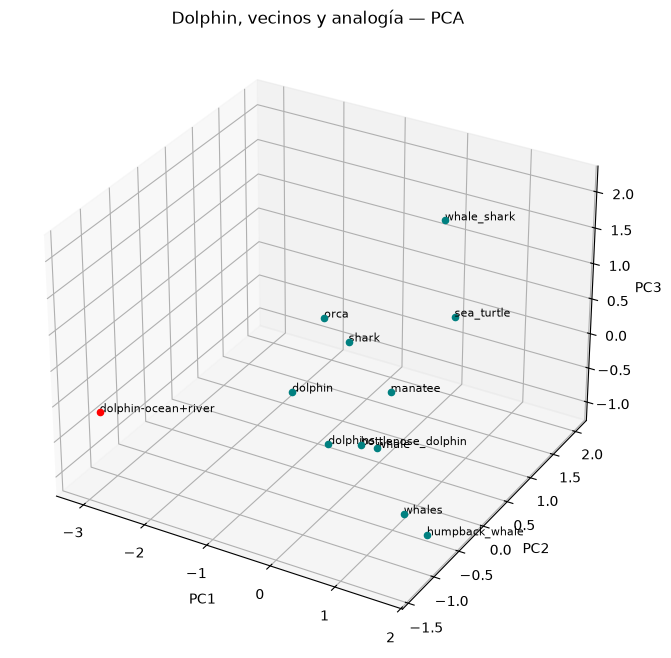

Varianza explicada en 3D: 0.47447854


2714

In [8]:
animal = "dolphin"  # Elección para este ejercicio, no dato personal de la estudiante.
assert animal in model.key_to_index
v_animal = model[animal]
neighbors = model.most_similar(animal, topn=10)
print("Dimensión:", v_animal.shape)
print("Vecinos:", neighbors)
operations = {
    "dog - domestic + wild": (["dog", "wild"], ["domestic"]),
    "eagle - fly + swim": (["eagle", "swim"], ["fly"]),
    "dolphin - ocean + river": (["dolphin", "river"], ["ocean"]),
}
results = {}
for label, (positive, negative) in operations.items():
    missing = [word for word in positive + negative if word not in model.key_to_index]
    if missing: raise KeyError(f"Palabras fuera del vocabulario: {missing}")
    results[label] = model.most_similar(positive=positive, negative=negative, topn=10)
    print(label, results[label])
operation_vector = model["dolphin"] - model["ocean"] + model["river"]
words = [animal] + [word for word, _ in neighbors] + ["dolphin-ocean+river"]
vectors = np.vstack([model[word] for word in words[:-1]] + [operation_vector])
pca_animals = PCA(n_components=3)
points = pca_animals.fit_transform(vectors)
fig = plt.figure(figsize=(11,8)); ax = fig.add_subplot(111, projection="3d")
for i, word in enumerate(words):
    ax.scatter(*points[i], color="red" if i==len(words)-1 else "teal")
    ax.text(*points[i], word, fontsize=8)
ax.set(xlabel="PC1",ylabel="PC2",zlabel="PC3",title="Dolphin, vecinos y analogía — PCA")
plt.show()
print("Varianza explicada en 3D:", pca_animals.explained_variance_ratio_.sum())
import json
from pathlib import Path
Path("semantic_results.json").write_text(json.dumps({"animal":animal,"neighbors":neighbors,
 "operations":results,"variance_3d":float(pca_animals.explained_variance_ratio_.sum())}, indent=2))

## Hipótesis e interpretación

Se eligió **dolphin** para explorar asociaciones acuáticas. Antes de ejecutar, se esperan cetáceos y términos del entorno marino. Para `dolphin - ocean + river` la hipótesis es desplazar asociaciones hacia agua dulce. Para dog se esperan animales silvestres y para eagle términos acuáticos, sin asumir que la aritmética sea una regla biológica.

Las listas y el PCA anteriores muestran los resultados calculados. Los embeddings reflejan coocurrencias del corpus periodístico: pueden incluir nombres propios, deportes y sesgos culturales; no son una taxonomía. PCA conserva solo parte de la varianza; cercanía en 3D no sustituye medir similitud en las 300 dimensiones originales. Se excluyen las palabras de entrada en most_similar con listas de palabras, para evitar devolver trivialmente el animal original.

## Resultados observados

Los vecinos de dolphin son coherentes: dolphins (0,832), whale (0,771), whale_shark (0,694), orca y sea_turtle. Whale_shark es un pez, no un cetáceo: la proximidad refleja contexto marino, no parentesco taxonómico.

`dog - domestic + wild` devuelve **cat** primero (0,544), aunque coyote aparece entre los resultados. La hipótesis de producir necesariamente un animal silvestre no se cumple. `eagle - fly + swim` devuelve **swimming**, pero también birdie y putt: eagle tiene un sentido asociado al golf. La operación inventada `dolphin - ocean + river` devuelve **dam** (0,514), brown_trout y crocodile; desplaza el contexto hacia ríos, pero no produce necesariamente un delfín de agua dulce.

Las tres componentes del PCA explican **47,45 %** de la varianza. Se observa la vecindad marina y el desplazamiento de la operación, pero se pierde más de la mitad de la variación; no se deben interpretar distancias del gráfico como distancias exactas del embedding original.
